# Count buildings in Argentina’s informal settlements

## Summary

In this tutorial, you’ll use open building footprints to count buildings in 6,467 of Argentina’s *barrios populares*, or informal settlements. You’ll use DuckDB to match the footprints to neighborhood boundaries from Argentina’s national registry, ReNaBaP. Then you’ll compare the building counts with the registry’s family estimates across the country and take a closer look at the former Club Planeadores in Los Hornos, La Plata.

This tutorial is an annex to *Del territorio al dato*, a technical note on how ReNaBaP was built and how open data can help keep it up to date.

## What you’ll need

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nlebovits/huellas-barrios-populares/blob/main/tutorial_python_en.ipynb)
<a href="tutorial_python_en.ipynb" download="tutorial_python_en.ipynb" data-noresolveinput="true">Download the notebook (.ipynb)</a>

To run the notebook in your browser, open it in Colab and sign in with a Google account. To run it on your computer, download it, open it in [VS Code](https://code.visualstudio.com/docs/datascience/jupyter-notebooks) or [Positron](https://positron.posit.co/positron-notebook-editor.html), and select your Python environment.

Run the cells from top to bottom. In the example run, the building file took up 5.6 GB.

### Data sources

A **building footprint** is the outline of a building as seen from above. Footprints show where buildings are within a neighborhood, which can help you decide where to check an older survey or which buildings to look at when mapping flood exposure.

| Dataset | What it contains | Version |
| --- | --- | --- |
| Overture Maps buildings | An outline for each mapped building | The notebook uses the latest release by default. The dates of the underlying imagery vary. |
| Registro Nacional de Barrios Populares (ReNaBaP) | A boundary and an approximate family count (`familias_aproximadas`) for each registered neighborhood | December 6, 2023 snapshot |

Overture publishes a global building dataset that combines sources including OpenStreetMap, government mapping such as the City of Vancouver’s building data, and footprints that Google and Microsoft detect in imagery. Overture documents its sources, how it combines them, and how to credit them when you reuse the data. [Overture buildings documentation](https://docs.overturemaps.org/guides/buildings/) · [Attribution and licensing](https://docs.overturemaps.org/attribution/).

ReNaBaP already uses imagery alongside field counts and estimates from community leaders to estimate how many homes are occupied. Open footprints let you run a building count across all registered neighborhoods in one query. For how the registry combined these sources, see **Territorio y detección remota: el ciclo del dato** in the technical note.

### Setup

Run the first cell to install the Python packages. Run the next cell to connect to DuckDB and look up the latest Overture release. The cell prints the release ID. To reproduce the results shown here, set `release` to `"2026-11-18.0"`.

In [1]:
#| output: false
%pip install -q duckdb geopandas folium mapclassify matplotlib geoparquet-io

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import duckdb
import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import requests

release = requests.get("https://stac.overturemaps.org/catalog.json").json()["latest"]
print("Overture release:", release)

Path("data").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

# Colors used in every figure.
BUILDINGS = "#1d6090"  # building footprints (CISUR blue)
BOUNDARY = "#F73484"  # ReNaBaP boundary (CISUR pink)
BASEMAP = "Esri.WorldGrayCanvas"  # plain gray background map
CREDIT = f"Data: Overture Maps Foundation ({release}), ReNaBaP (Dec 6, 2023)"

# DuckDB reads and joins big files without loading them into memory.
con = duckdb.connect()
con.sql("INSTALL spatial; LOAD spatial; INSTALL httpfs; LOAD httpfs;")
con.sql("SET s3_region = 'us-west-2'")

Overture release: 2026-11-18.0


## Import the data

**Download the ReNaBaP boundaries.** The first cell downloads the registry as GeoJSON and converts it to GeoParquet, a file format for map data that DuckDB can query directly. The output shows **6,467 neighborhoods** and an estimated **1,237,795 families**.

In [3]:
renabap_geojson = "data/renabap_2023-12-06.geojson"
renabap_path = "data/renabap_2023-12-06.parquet"

if not Path(renabap_geojson).exists():
    url = "https://www.argentina.gob.ar/sites/default/files/renabap-2023-12-06.geojson"
    Path(renabap_geojson).write_bytes(requests.get(url).content)

if not Path(renabap_path).exists():
    !gpio convert {renabap_geojson} {renabap_path}

settlements = gpd.read_parquet(renabap_path).drop(columns="OGC_FID")
print(f"{len(settlements):,} neighborhoods, "
      f"{settlements.familias_aproximadas.sum():,} families")
settlements.head()

6,467 neighborhoods, 1,237,795 families


,id_renabap,nombre_barrio,provincia,departamento,localidad,familias_aproximadas,geom
0,4897,Sin Nombre,Santa Cruz,Güer Aike,28 De Noviembre,39,"MULTIPOLYGON (((-72.21496 -51.60048, -72.21562..."
1,4887,José Obrero,Santa Cruz,Corpen Aike,Comandante Luis Piedrabuena,94,"MULTIPOLYGON (((-68.91092 -49.9705, -68.90679 ..."
2,4896,Obrero,Santa Cruz,Deseado,Pico Truncado,28,"MULTIPOLYGON (((-67.93751 -46.79967, -67.93877..."
3,4895,Zona de Chacras,Santa Cruz,Deseado,Pico Truncado,132,"MULTIPOLYGON (((-67.93262 -46.79167, -67.93714..."
4,3759,Madres A La Lucha,Santa Cruz,Güer Aike,Río Gallegos,550,"MULTIPOLYGON (((-69.18149 -51.64052, -69.1799 ..."


**Download the Overture footprints.** The next cell uses a rectangle around Argentina to select buildings from Overture’s global dataset. The rectangle includes parts of neighboring countries. The next query uses the neighborhood boundaries to determine which footprints count. If you rerun the notebook with the same release, it reuses the downloaded file.

In [4]:
buildings_path = f"data/buildings_{release}.parquet"
overture = f"s3://overturemaps-us-west-2/release/{release}/theme=buildings/type=building/*"

if not Path(buildings_path).exists():
    con.sql(f"""
        COPY (
            SELECT id, geometry, bbox, sources[1].dataset AS source
            FROM read_parquet('{overture}')
            WHERE bbox.xmin > -73.6 AND bbox.xmax < -53.6
              AND bbox.ymin > -55.1 AND bbox.ymax < -21.7
        ) TO '{buildings_path}'
    """)

print(f"Downloaded {Path(buildings_path).stat().st_size / 1e9:.1f} GB")
con.sql(f"SELECT count(*) AS buildings FROM '{buildings_path}'").df()

Downloaded 5.6 GB


,buildings
0,45919463


## Count buildings in each settlement

Run the query to count footprints within each ReNaBaP neighborhood. DuckDB picks a point inside each footprint, then checks which neighborhood boundaries contain that point. This is called a **spatial join** because it matches records by location.

Using one point gives the query a rule for footprints that cross a boundary. The output table shows the family estimate next to the building count for each neighborhood. A neighborhood with no matching footprints gets a count of zero.

In [5]:
counts = con.sql(f"""
    SELECT s.id_renabap, count(*) AS buildings
    FROM '{buildings_path}' AS b
    JOIN '{renabap_path}' AS s
      ON ST_Contains(s.geom, ST_PointOnSurface(b.geometry))
    GROUP BY s.id_renabap
""").df()

settlements = settlements.merge(counts, on="id_renabap", how="left")
settlements["buildings"] = settlements.buildings.fillna(0).astype(int)
settlements["buildings_per_family"] = (
    settlements.buildings / settlements.familias_aproximadas
)
settlements[["nombre_barrio", "provincia", "familias_aproximadas", "buildings"]].head()

,nombre_barrio,provincia,familias_aproximadas,buildings
0,Sin Nombre,Santa Cruz,39,78
1,José Obrero,Santa Cruz,94,284
2,Obrero,Santa Cruz,28,27
3,Zona de Chacras,Santa Cruz,132,437
4,Madres A La Lucha,Santa Cruz,550,425


## Compare buildings with estimated families

Divide the building count by the family estimate for each neighborhood. A ratio of 2 means the query counted two footprints for every family in the registry estimate.

The ratio depends in part on how a neighborhood is built. In a dense urban settlement, several families may share a building or live on different floors. Homes with adjoining roofs can also appear as a single footprint. In a more spread-out rural settlement, one family may use several separate buildings, such as a house, a kitchen, and a shed.

A large gap gives you a place to look more closely. It could reflect growth since a survey, the layout and use of buildings, or errors in the footprint data. Even when the counts are close, estimating population requires local information about occupancy and household size. See **Territorios dinámicos, nuevas herramientas y nuevos desafíos** in the technical note for more on using footprints alongside survey data.

Run the next cell to see how the ratios vary across neighborhoods and find the ten places where the building count exceeds the family estimate by the most.

In [6]:
groups = ["Below 0.5", "0.5 to 0.8", "0.8 to 1.25", "1.25 to 2", "Above 2"]
settlements["ratio_group"] = pd.cut(
    settlements.buildings_per_family,
    bins=[0, 0.5, 0.8, 1.25, 2, float("inf")],
    labels=groups, right=False,
)

print(f"Registered families: {settlements.familias_aproximadas.sum():,}")
print(f"Buildings inside neighborhoods: {settlements.buildings.sum():,}")
display(settlements.ratio_group.value_counts().reindex(groups).rename("neighborhoods"))

settlements["gap"] = settlements.buildings - settlements.familias_aproximadas
settlements.nlargest(10, "gap")[
    ["id_renabap", "nombre_barrio", "localidad", "provincia",
     "familias_aproximadas", "buildings"]
]

Registered families: 1,237,795
Buildings inside neighborhoods: 1,398,441


ratio_group
Below 0.5       490
0.5 to 0.8      786
0.8 to 1.25    1910
1.25 to 2      2305
Above 2         976
Name: neighborhoods, dtype: int64

,id_renabap,nombre_barrio,localidad,provincia,familias_aproximadas,buildings
6186,6541,Sin Nombre,Los Hornos,Buenos Aires,330,3771
4288,3037,Santa Rosa de Lima,Santa Fe,Santa Fe,1166,3390
3707,1235,Amancay,Maquinista Savio,Buenos Aires,935,2834
1972,3527,General Paz,Santiago Del Estero,Santiago del Estero,484,2381
952,3050,Francisco I y II,La Rioja,La Rioja,149,2022
3479,5375,Río Alegre,Mariano Acosta,Buenos Aires,430,2207
3315,5293,Diecisiete de Septiembre,González Catán,Buenos Aires,1650,3293
48,4219,Los Productores,Río Grande,Tierra del Fuego,363,1857
4285,2975,Los Troncos,Santa Fe,Santa Fe,880,2358
5501,4180,2000 Hectareas,Puerto Iguazú,Misiones,429,1893


**Figure 1. Footprints and estimated families by neighborhood.** Each dot represents a neighborhood with at least one matched footprint. Dots above the dashed line have more footprints than estimated families. Both axes use a logarithmic scale so neighborhoods of very different sizes fit on the same chart.

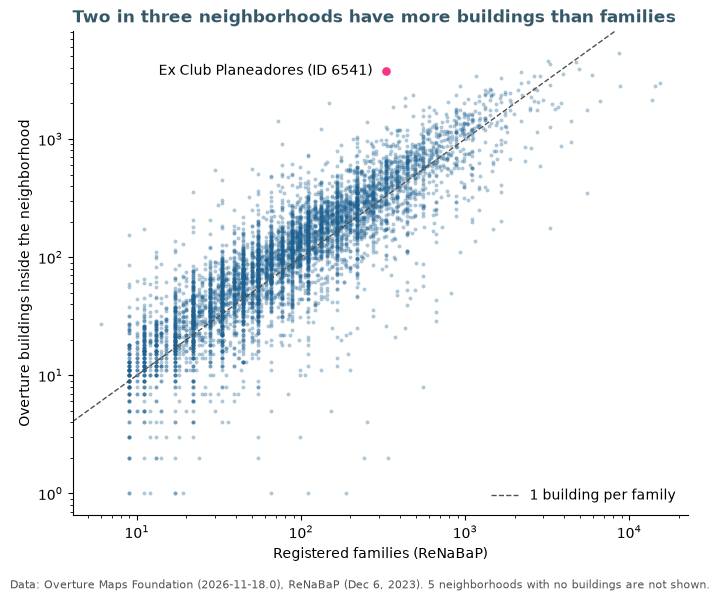

In [7]:
case_id = 6541  # former Club Planeadores, see the next section
plotted = settlements[settlements.buildings > 0]
case = settlements[settlements.id_renabap == case_id]

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(plotted.familias_aproximadas, plotted.buildings,
           s=8, color=BUILDINGS, alpha=0.35, linewidths=0)
ax.scatter(case.familias_aproximadas, case.buildings,
           s=60, color=BOUNDARY, edgecolor="white", linewidth=1.5, zorder=3)
ax.annotate("Ex Club Planeadores (ID 6541)",
            (case.familias_aproximadas.iloc[0], case.buildings.iloc[0]),
            xytext=(-10, 0), textcoords="offset points", va="center", ha="right")
ax.axline((10, 10), slope=1, color="#52514e", linestyle="--", linewidth=1,
          label="1 building per family")
ax.legend(loc="lower right", frameon=False)
ax.set(xscale="log", yscale="log",
       xlabel="Registered families (ReNaBaP)",
       ylabel="Overture buildings inside the neighborhood")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Two in three neighborhoods have more buildings than families",
             loc="left", fontweight="bold", color="#355868")
fig.text(0.01, 0.01, CREDIT + f". {len(settlements) - len(plotted)} neighborhoods "
         "with no buildings are not shown.", fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("outputs/buildings_vs_families.png", dpi=200)
plt.show()

**Figure 2. Footprints per estimated family across Argentina.** Zoom in and hover over a dot to see the neighborhood’s name and both counts.

In [8]:
dots = settlements.copy()
dots.geometry = dots.geometry.representative_point()

national_map = dots.explore(
    column="ratio_group",
    cmap=["#1d6090", "#7fa6c9", "#a3a29c", "#f58db5", "#c8105f"],
    tiles=BASEMAP,
    marker_kwds={"radius": 4},
    style_kwds={"fillOpacity": 0.9, "weight": 0},
    tooltip=["nombre_barrio", "localidad", "provincia",
             "familias_aproximadas", "buildings"],
    legend_kwds={"caption": "Buildings per registered family"},
)
national_map.save("outputs/national_map.html")
national_map

## Zoom in on the former Club Planeadores

The neighborhood on the former Club Planeadores grounds in Los Hornos, La Plata, had the largest gap in the example run. The query counted **3,771 footprints** within the registry boundary, and ReNaBaP lists an estimated **330 families**. The technical note describes how the neighborhood grew and why it’s a useful place to investigate the gap.

ReNaBaP lists several neighborhoods in Los Hornos as *Sin Nombre*. Use the registry ID, `6541`, to identify this one. Run the next cells to pull out its footprints and see which source supplied them.

In [9]:
settlements.loc[
    (settlements.localidad == "Los Hornos")
    & (settlements.nombre_barrio == "Sin Nombre"),
    ["id_renabap", "nombre_barrio", "familias_aproximadas", "buildings"],
]

,id_renabap,nombre_barrio,familias_aproximadas,buildings
6123,43,Sin Nombre,32,42
6124,46,Sin Nombre,330,477
6186,6541,Sin Nombre,330,3771
6188,1034,Sin Nombre,66,64
6189,863,Sin Nombre,209,370
6196,1055,Sin Nombre,133,203
6198,79,Sin Nombre,275,514
6222,49,Sin Nombre,143,240


In [10]:
boundary = settlements[settlements.id_renabap == case_id]
west, south, east, north = boundary.total_bounds

planeadores = gpd.GeoDataFrame.from_arrow(con.sql(f"""
    SELECT b.id, b.source, b.geometry
    FROM '{buildings_path}' AS b
    JOIN '{renabap_path}' AS s
      ON ST_Contains(s.geom, ST_PointOnSurface(b.geometry))
    WHERE s.id_renabap = {case_id}
      AND b.bbox.xmin < {east} AND b.bbox.xmax > {west}
      AND b.bbox.ymin < {north} AND b.bbox.ymax > {south}
""").arrow())

print(f"{len(planeadores):,} buildings, "
      f"{boundary.familias_aproximadas.iloc[0]:,} registered families")
planeadores.source.value_counts().rename("buildings by source")

3,771 buildings, 330 registered families


source
Google Open Buildings     3741
Microsoft ML Buildings      30
Name: buildings by source, dtype: int64

**Figure 3. Building footprints at the former Club Planeadores.** The blue shapes are footprints, and the pink line is the registry boundary. Open the layer control in the upper-right corner and select **Satellite imagery (Esri)** to compare the footprints with visible roofs. Look for roofs with no matching outline, outlines you can’t match to a roof, and adjoining roofs grouped into a single footprint. The map imagery and the imagery used to create the footprints may have been taken at different times.

In [11]:
local_map = planeadores.explore(
    color=BUILDINGS, tiles=BASEMAP, name="Building footprints",
    tooltip=["id", "source"],
    style_kwds={"weight": 0, "fillOpacity": 0.8},
)
boundary.explore(m=local_map, color=BOUNDARY, name="ReNaBaP boundary",
                 tooltip=["nombre_barrio", "id_renabap", "familias_aproximadas"],
                 style_kwds={"fill": False, "weight": 3})
folium.TileLayer(
    "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    name="Satellite imagery (Esri)", attr="Esri and imagery contributors",
    show=False,  # start on the gray map, where the footprints stand out
).add_to(local_map)
folium.LayerControl().add_to(local_map)
local_map.save("outputs/planeadores_map.html")
local_map

## Next steps

Try this workflow in a neighborhood you know. Change `case_id` to its ReNaBaP ID and rerun the cells from Figure 1 onward. Look at where the footprint count and the family estimate differ, then work with residents, community organizations, local survey teams, or others who know the area to check a few blocks on the ground.

Find out which buildings are homes, where several families share a building, and which structures the map missed. If you have a recent survey or dated imagery, use it to help distinguish changes in the neighborhood from gaps in the footprint data. The technical note’s **Territorio y detección remota: el ciclo del dato** section describes how ReNaBaP combined these kinds of checks.

Share what you find with others working nearby and try the comparison in a neighborhood built differently. What you learn can help you decide where footprints are useful in your area, whether that’s choosing blocks to revisit in a survey or identifying buildings to check against a flood map.

*The references to the technical note use its current section titles. They can link directly to those sections once the note has a published URL.*